# Cold–warm: trend plots

_Plots only — run `cw_calculations.ipynb` first. 20% ranges removed._


In [1]:
# Load Packages
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [2]:
import sys, os
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [3]:
# Load variables computed in cw_calculations.ipynb
load_state(globals())


[load_state] loaded 169 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, ax, c, cmap, cmip_xmean, cmip_ymean, cold20_cmip, cold20_cmip_trim ...


{'In': ['',
  '# Load Packages \n\nimport numpy as np\nimport xarray as xr\nimport matplotlib.pyplot as plt\nimport math\nimport cartopy.crs as ccrs\nimport calendar\nfrom matplotlib.lines import Line2D\nimport os\nimport re\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm\n# from mpl_toolkits.basemap import Basemap\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom scipy.stats import scoreatpercentile\n# import xesmf as xe\nfrom matplotlib.gridspec import GridSpec\nimport matplotlib\nfrom pathlib import Path',
  "import sys, os\n# make this repo's functions.py importable from any subfolder\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "# Load variables produced by earlier (compute/loader) notebooks.\

In [4]:
# load gridded data processed in gadi 
from datetime import datetime


mod_labs = ['MRI-ESM2-0', 'FGOALS-f3-L','EC-EARTH3','ACCESS-OM2-JRA55-cycle6_iaf','ACCESS-OM2-ERA5']

save_directory = '/Users/isabelaconde/Desktop/data/omip/tos/'

file_paths = [f"{save_directory}tos_global_{model}_1982-2018_gr.nc" for model in mod_labs]
gr_omip_mean = {}

td = datetime.strptime("1982-01-01", "%Y-%m-%d")
k = 444
d = pd.date_range(td, periods=k, freq='MS')


for i, path in enumerate(file_paths):
    ds = xr.open_dataarray(path)
    ds = ds.assign_coords({'time': d})
    gr_omip_mean[mod_labs[i]] = xr.open_dataarray(path).mean(dim = 'time')

# gr_omip['MRI-ESM2-0']

27.329655
27.279894
27.485382
27.397161
27.536604


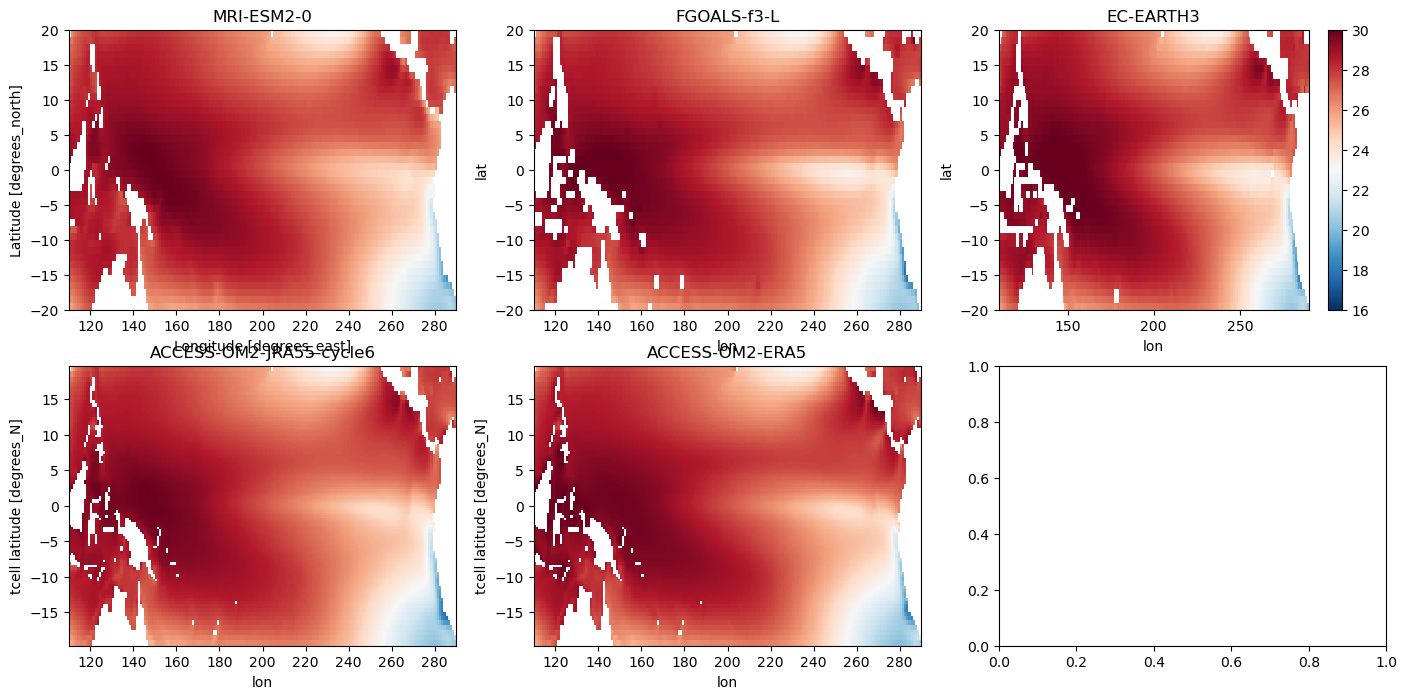

In [5]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(17, 8))
axes = axes.flatten()  # Make it 1D so you can index with i
labels = ['MRI-ESM2-0', 'FGOALS-f3-L','EC-EARTH3','ACCESS-OM2-JRA55-cycle6','ACCESS-OM2-ERA5','NOAA-GFDL']
for i, da in enumerate(gr_omip_mean):
    im = (gr_omip_mean[da].sel(lon = slice(110,290), lat = slice(-20,20))).plot(ax=axes[i], add_colorbar=False, cmap='RdBu_r', vmin=16, vmax=30)
    print(gr_omip_mean[da].sel(lon = slice(110,290), lat = slice(-20,20)).mean(dim = ['lat','lon']).values)
    axes[i].set_title(labels[i])
        # Add colorbar only to axes[1] and axes[4] (i.e. subplots 2 and 5)
    if i in [2, 5]:
        cbar = fig.colorbar(im, ax=axes[i], orientation='vertical')

In [ ]:
for i, da in enumerate(gr_omip_mean):
    print(da)
